<a href="https://colab.research.google.com/github/saheltai9-cyber/Customer-Segmentation-AI/blob/main/02_Customer_Segmentation_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Project 02 — Customer Segmentation AI
Complete, self-contained Google Colab workflow. Run the single code cell below from top to bottom. It downloads the Mall Customers dataset, performs EDA and cleaning, scales the features, selects K using Silhouette/Davies-Bouldin, trains K-Means, evaluates clusters, predicts a new customer, saves the model/reports, and creates a ZIP.

Required libraries are already installed.
Using existing dataset: /content/Customer-Segmentation-Colab/data/raw/Mall_Customers.csv

DATASET VERIFIED
Rows loaded: 200
Exact duplicate rows removed: 0
Rows with missing model features removed: 0
Final shape: (200, 5)
Data source: /content/Customer-Segmentation-Colab/data/raw/Mall_Customers.csv


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


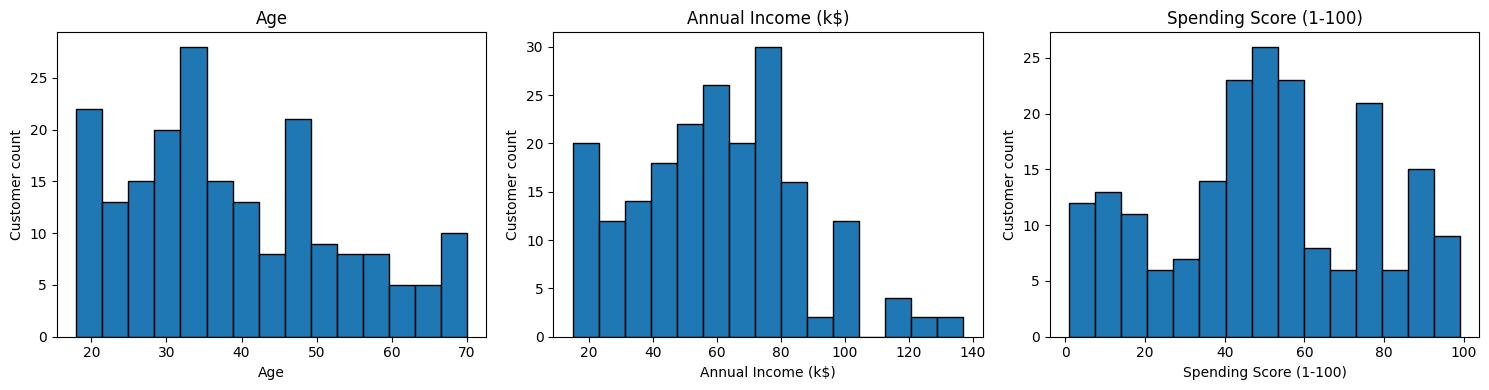


K SELECTION RESULTS


,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,389.3862,0.3355,1.2607,107.0956
1,3,295.2122,0.3578,1.0503,101.6949
2,4,205.2251,0.4040,0.9308,125.6764
3,5,168.2476,0.4166,0.8746,125.1009
4,6,133.8683,0.4274,0.8277,135.1022
5,7,117.0116,0.4172,0.7935,132.7743
6,8,103.8286,0.4087,0.8893,131.0744
7,9,92.3495,0.4201,0.8541,131.2423
8,10,81.9871,0.3973,0.9056,133.3848


Selected K: 6
Silhouette: 0.4274
Davies-Bouldin: 0.8277
Calinski-Harabasz: 135.1


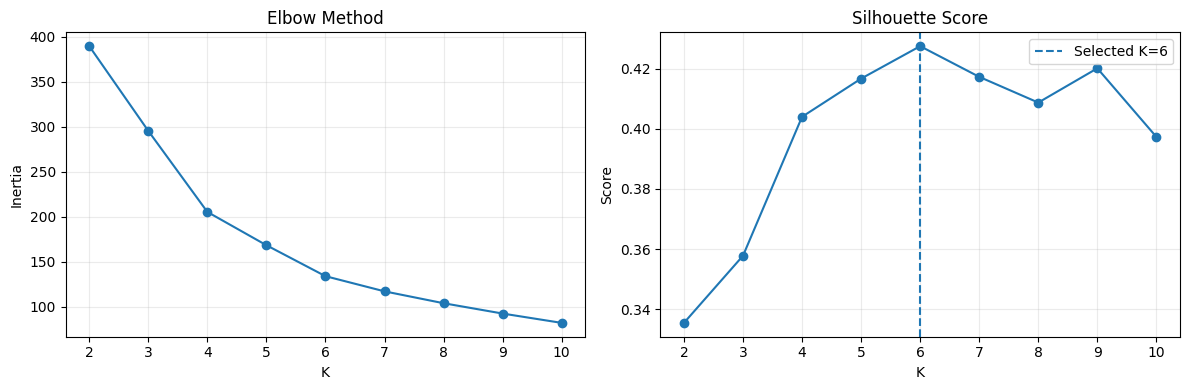


CUSTOMER SEGMENT PROFILES


,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score,Customer_Percentage
Cluster,,,,,
0,33,41.94,88.94,16.97,16.5
1,45,56.33,54.27,49.07,22.5
2,24,25.25,25.83,76.92,12.0
3,39,32.69,86.54,82.13,19.5
4,38,26.68,57.58,47.79,19.0
5,21,45.52,26.29,19.38,10.5


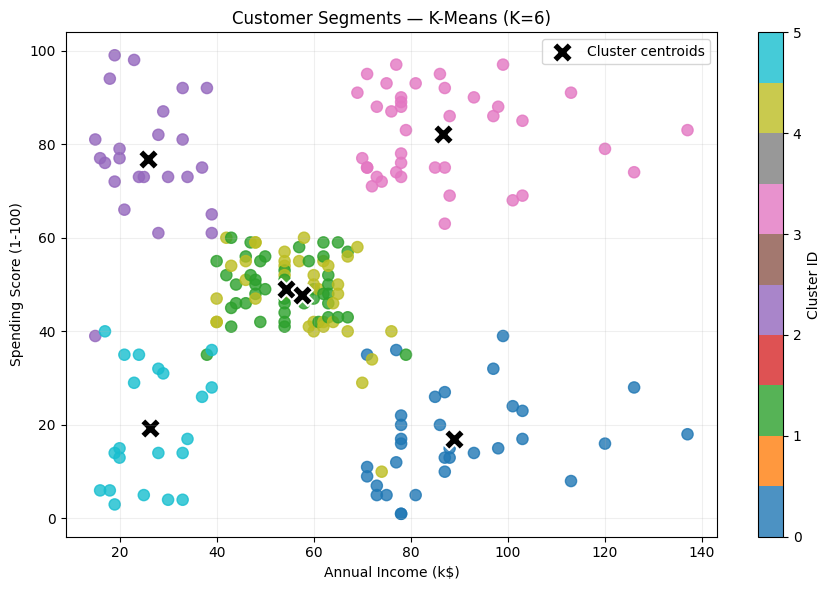


NEW CUSTOMER PREDICTION
Age: 25
Annual Income (k$): 85
Spending Score: 85
Predicted Cluster ID: 3
This cluster's profile:


,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score,Customer_Percentage
Cluster,,,,,
3,39,32.69,86.54,82.13,19.5



AUTOMATED SANITY CHECKS
PASS — 200-row dataset (or larger validated dataset)
PASS — All rows assigned to a cluster
PASS — At least two clusters produced
PASS — Saved model exists
PASS — Saved model reproduces prediction
PASS — Evaluation and profiles saved

PROJECT 02 — COLAB PIPELINE COMPLETED
Customers: 200
Selected K: 6
Silhouette: 0.4274
Davies-Bouldin: 0.8277
Sample customer predicted cluster: 3
Sanity checks: 6 / 6 PASSED
Saved model: /content/Customer-Segmentation-Colab/models/pipeline.joblib
Reports: /content/Customer-Segmentation-Colab/reports
Results ZIP: /content/Customer-Segmentation-Colab-Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# ============================================================
# PROJECT 02 — CUSTOMER SEGMENTATION AI
# COMPLETE, SELF-CONTAINED GOOGLE COLAB PIPELINE
# ============================================================

import sys, subprocess, importlib.util, urllib.request, json, zipfile
from pathlib import Path

# 1) Install only libraries missing from this Colab runtime.
packages = {"numpy": "numpy", "pandas": "pandas",
            "sklearn": "scikit-learn", "matplotlib": "matplotlib",
            "joblib": "joblib"}
missing = [pkg for mod, pkg in packages.items()
           if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("Required libraries are already installed.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from IPython.display import display

# 2) Create a fresh, independent Colab project folder.
# This deliberately does NOT call the incomplete GitHub train.py/src imports.
PROJECT = Path("/content/Customer-Segmentation-Colab")
RAW = PROJECT / "data" / "raw"
PROCESSED = PROJECT / "data" / "processed"
MODELS = PROJECT / "models"
REPORTS = PROJECT / "reports"
FIGURES = REPORTS / "figures"

for folder in [RAW, PROCESSED, MODELS, REPORTS, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

# 3) Download the same 200-row Mall Customers dataset referenced in the repo README.
DATA_PATH = RAW / "Mall_Customers.csv"
DATA_URLS = [
    "https://raw.githubusercontent.com/tanishq21/Mall-Customers/main/Mall_Customers.csv",
    "https://raw.githubusercontent.com/iamctodd/datasets/main/mall_customers.csv",
    "https://raw.githubusercontent.com/rithwik00/Mall-Customer-Dataset/main/Mall_Customers.csv",
]
data_source = None

if DATA_PATH.exists():
    data_source = str(DATA_PATH)
    print("Using existing dataset:", DATA_PATH)
else:
    errors = []
    for url in DATA_URLS:
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=40) as response:
                content = response.read()
            if len(content) < 1000:
                raise ValueError("Downloaded file is unexpectedly small.")
            DATA_PATH.write_bytes(content)
            data_source = url
            print("Dataset downloaded:", url)
            break
        except Exception as exc:
            errors.append(f"{url}: {type(exc).__name__}: {exc}")
    if data_source is None:
        raise RuntimeError("Could not download the dataset:\n" + "\n".join(errors))

# 4) Load and validate the actual dataset.
df = pd.read_csv(DATA_PATH)
df.columns = [str(c).strip() for c in df.columns]

# Dataset mirrors may call this column Gender instead of Genre.
if "Gender" in df.columns and "Genre" not in df.columns:
    df.rename(columns={"Gender": "Genre"}, inplace=True)

FEATURES = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
REQUIRED = ["CustomerID"] + FEATURES
missing_columns = [c for c in REQUIRED if c not in df.columns]
if missing_columns:
    raise ValueError(
        f"Dataset columns are incorrect. Missing: {missing_columns}. "
        f"Found: {df.columns.tolist()}"
    )

rows_before = len(df)
duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Rows lacking a core model feature cannot be used in distance-based K-Means.
missing_feature_rows = int(df[FEATURES].isna().any(axis=1).sum())
df = df.dropna(subset=FEATURES).reset_index(drop=True)

if len(df) < 20:
    raise ValueError(f"Only {len(df)} valid rows remain; dataset looks incomplete.")
if (df["Age"] <= 0).any():
    raise ValueError("Age contains zero or negative values.")
if (df["Annual Income (k$)"] < 0).any():
    raise ValueError("Annual income contains negative values.")
if not df["Spending Score (1-100)"].between(1, 100).all():
    raise ValueError("Spending Score must be between 1 and 100.")

print("\nDATASET VERIFIED")
print("Rows loaded:", rows_before)
print("Exact duplicate rows removed:", duplicate_count)
print("Rows with missing model features removed:", missing_feature_rows)
print("Final shape:", df.shape)
print("Data source:", data_source)
display(df.head())
display(df[FEATURES].describe().round(2))

# 5) EDA: feature distributions.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, FEATURES):
    ax.hist(df[col], bins=15, edgecolor="black")
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Customer count")
plt.tight_layout()
plt.savefig(FIGURES / "feature_distributions.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

# CustomerID is only an identifier; Genre/Gender is descriptive.
# The model uses the same three numeric features as the project's prediction code.
X = df[FEATURES].copy()

# 6) Scale features and evaluate candidate K values (2 through 10).
# For unsupervised K-Means, use internal clustering metrics, not classification accuracy.
search_scaler = StandardScaler()
X_scaled = search_scaler.fit_transform(X)

results = []
for k in range(2, min(10, len(df) - 1) + 1):
    candidate = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = candidate.fit_predict(X_scaled)

    if len(np.unique(labels)) < 2:
        continue

    results.append({
        "k": int(k),
        "inertia": float(candidate.inertia_),
        "silhouette": float(silhouette_score(X_scaled, labels)),
        "davies_bouldin": float(davies_bouldin_score(X_scaled, labels)),
        "calinski_harabasz": float(calinski_harabasz_score(X_scaled, labels))
    })

if not results:
    raise RuntimeError("No valid K-Means configurations could be evaluated.")

evaluation = pd.DataFrame(results)
evaluation.to_csv(REPORTS / "cluster_evaluation.csv", index=False)

# Select highest Silhouette; use lower Davies-Bouldin as tie-breaker.
best = evaluation.sort_values(
    ["silhouette", "davies_bouldin"], ascending=[False, True]
).iloc[0]
BEST_K = int(best["k"])

print("\nK SELECTION RESULTS")
display(evaluation.round(4))
print("Selected K:", BEST_K)
print("Silhouette:", round(float(best["silhouette"]), 4))
print("Davies-Bouldin:", round(float(best["davies_bouldin"]), 4))
print("Calinski-Harabasz:", round(float(best["calinski_harabasz"]), 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(evaluation["k"], evaluation["inertia"], marker="o")
axes[0].set(title="Elbow Method", xlabel="K", ylabel="Inertia")
axes[0].grid(alpha=0.25)
axes[1].plot(evaluation["k"], evaluation["silhouette"], marker="o")
axes[1].axvline(BEST_K, linestyle="--", label=f"Selected K={BEST_K}")
axes[1].set(title="Silhouette Score", xlabel="K", ylabel="Score")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURES / "optimal_k_selection.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

# 7) Train a reusable pipeline: scaler + KMeans.
# This stores preprocessing and clustering together, so inference uses identical scaling.
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=BEST_K, random_state=42, n_init=20))
])
pipeline.fit(X)

df_scored = df.copy()
df_scored["Cluster"] = pipeline.predict(X)
MODEL_PATH = MODELS / "pipeline.joblib"
joblib.dump(pipeline, MODEL_PATH)

# 8) Generate customer profiles.
profiles = (
    df_scored.groupby("Cluster")
    .agg(
        Customer_Count=("CustomerID", "count"),
        Average_Age=("Age", "mean"),
        Average_Annual_Income=("Annual Income (k$)", "mean"),
        Average_Spending_Score=("Spending Score (1-100)", "mean")
    )
    .round(2)
)
profiles["Customer_Percentage"] = (
    profiles["Customer_Count"] / len(df_scored) * 100
).round(2)
profiles.to_csv(REPORTS / "cluster_profiles.csv")
df_scored.to_csv(PROCESSED / "customer_segments.csv", index=False)

print("\nCUSTOMER SEGMENT PROFILES")
display(profiles)

# 9) Visualize the clusters using Income vs Spending Score.
centers_raw = pipeline.named_steps["scaler"].inverse_transform(
    pipeline.named_steps["kmeans"].cluster_centers_
)
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    df_scored["Annual Income (k$)"],
    df_scored["Spending Score (1-100)"],
    c=df_scored["Cluster"], cmap="tab10", s=65, alpha=0.8
)
plt.scatter(
    centers_raw[:, 1], centers_raw[:, 2],
    marker="X", s=230, c="black", edgecolors="white",
    linewidths=1.5, label="Cluster centroids"
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title(f"Customer Segments — K-Means (K={BEST_K})")
plt.colorbar(scatter, label="Cluster ID")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURES / "customer_clusters.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

# 10) Predict a new customer through the SAVED pipeline.
def predict_cluster(age, annual_income, spending_score, model=pipeline):
    sample = pd.DataFrame(
        [[float(age), float(annual_income), float(spending_score)]],
        columns=FEATURES
    )
    if sample.isna().any().any():
        raise ValueError("All customer inputs must be numeric.")
    if sample.loc[0, "Age"] <= 0 or sample.loc[0, "Annual Income (k$)"] < 0:
        raise ValueError("Age must be positive and income cannot be negative.")
    if not sample.loc[0, "Spending Score (1-100)"] in range(1, 101):
        raise ValueError("Spending Score must be from 1 to 100.")
    return int(model.predict(sample)[0])

sample_customer = {"age": 25, "annual_income": 85, "spending_score": 85}
sample_cluster = predict_cluster(**sample_customer)

print("\nNEW CUSTOMER PREDICTION")
print("Age:", sample_customer["age"])
print("Annual Income (k$):", sample_customer["annual_income"])
print("Spending Score:", sample_customer["spending_score"])
print("Predicted Cluster ID:", sample_cluster)
print("This cluster's profile:")
display(profiles.loc[[sample_cluster]])

# 11) Save genuine evaluation metrics and validate model persistence.
metrics = {
    "project": "Customer Segmentation AI",
    "dataset_source": data_source,
    "rows_after_cleaning": int(len(df_scored)),
    "features_used": FEATURES,
    "excluded_from_clustering": ["CustomerID", "Genre/Gender"],
    "selected_k": BEST_K,
    "selection_rule": "Highest Silhouette; lowest Davies-Bouldin as tie-breaker",
    "silhouette_score": float(best["silhouette"]),
    "davies_bouldin_score": float(best["davies_bouldin"]),
    "calinski_harabasz_score": float(best["calinski_harabasz"]),
    "inertia": float(best["inertia"]),
    "random_state": 42,
    "n_init": 20,
    "evaluation_note": "Unsupervised internal clustering metrics; not classification accuracy."
}
(REPORTS / "model_metrics.json").write_text(
    json.dumps(metrics, indent=2), encoding="utf-8"
)

# Reload and confirm the saved artifact makes exactly the same prediction.
loaded_pipeline = joblib.load(MODEL_PATH)
sample_frame = pd.DataFrame(
    [[sample_customer["age"], sample_customer["annual_income"],
      sample_customer["spending_score"]]],
    columns=FEATURES
)
before_save = pipeline.predict(sample_frame)
after_load = loaded_pipeline.predict(sample_frame)

# 12) Automated sanity checks.
checks = {
    "200-row dataset (or larger validated dataset)": len(df_scored) >= 20,
    "All rows assigned to a cluster": df_scored["Cluster"].notna().all(),
    "At least two clusters produced": df_scored["Cluster"].nunique() >= 2,
    "Saved model exists": MODEL_PATH.exists() and MODEL_PATH.stat().st_size > 0,
    "Saved model reproduces prediction": np.array_equal(before_save, after_load),
    "Evaluation and profiles saved": (
        (REPORTS / "cluster_evaluation.csv").exists()
        and (REPORTS / "cluster_profiles.csv").exists()
    )
}
print("\nAUTOMATED SANITY CHECKS")
for name, passed in checks.items():
    print(("PASS" if passed else "FAIL") + " — " + name)
if not all(checks.values()):
    raise AssertionError("One or more sanity checks failed.")

# 13) Save README, requirements, and a portable results ZIP.
readme = f"""# Customer Segmentation AI — Google Colab

## Objective
Group mall customers by age, annual income, and spending score using K-Means clustering.

## Dataset
Mall Customers dataset. Source: {data_source}

## Pipeline
1. Dataset loading and schema validation
2. Duplicate and missing-value checks
3. Exploratory Data Analysis
4. StandardScaler feature scaling
5. K-Means selection for K=2 through 10
6. Silhouette, Davies-Bouldin, Calinski-Harabasz, and inertia evaluation
7. Final scaler + K-Means pipeline
8. Customer cluster profiles
9. New customer prediction
10. Model save/load verification

## Selected model
K = {BEST_K}
Silhouette = {metrics['silhouette_score']:.4f}
Davies-Bouldin = {metrics['davies_bouldin_score']:.4f}

## Evaluation note
This is unsupervised learning. Classification accuracy is not an appropriate metric. The scores above are internal cluster-validation metrics.

## Outputs
- data/raw/Mall_Customers.csv
- data/processed/customer_segments.csv
- models/pipeline.joblib
- reports/cluster_evaluation.csv
- reports/cluster_profiles.csv
- reports/model_metrics.json
- reports/figures/*.png
"""
(PROJECT / "README.md").write_text(readme, encoding="utf-8")
(PROJECT / "requirements-colab.txt").write_text(
    "numpy\npandas\nscikit-learn\nmatplotlib\njoblib\n",
    encoding="utf-8"
)

ZIP_PATH = Path("/content/Customer-Segmentation-Colab-Results.zip")
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as archive:
    for file_path in PROJECT.rglob("*"):
        if file_path.is_file():
            archive.write(file_path, file_path.relative_to(PROJECT.parent))

print("\n" + "=" * 58)
print("PROJECT 02 — COLAB PIPELINE COMPLETED")
print("=" * 58)
print("Customers:", len(df_scored))
print("Selected K:", BEST_K)
print("Silhouette:", round(metrics["silhouette_score"], 4))
print("Davies-Bouldin:", round(metrics["davies_bouldin_score"], 4))
print("Sample customer predicted cluster:", sample_cluster)
print("Sanity checks:", sum(checks.values()), "/", len(checks), "PASSED")
print("Saved model:", MODEL_PATH)
print("Reports:", REPORTS)
print("Results ZIP:", ZIP_PATH)
print("=" * 58)

# Automatically download the results ZIP when running in Google Colab.
try:
    from google.colab import files
    files.download(str(ZIP_PATH))
except Exception:
    print("Not in Google Colab. Results ZIP is at:", ZIP_PATH)
